# 2 · Control theory: from one unstable pole to the Tumbller's three loops

**Tumbller balance course — notebook 2 of 4.**

Notebook 1 gave us the plant: $\dot s = A s + B u$ with one eigenvalue in the
right half-plane. This notebook builds, step by step, the controller that the
Elegoo firmware actually runs — and explains each piece before adding the next.

**You should come out knowing:**
- why a PD law on the tilt angle stabilises the pendulum, and what P and D each do;
- why balancing alone is not enough (the robot runs away), and why the speed
  loop uses **positive** feedback;
- what the integral term buys (standing still, tolerance to a wrong zero angle);
- why the speed loop must be *slow*, and what sampling does to stability;
- how tilt is estimated from an accelerometer and a gyro (complementary / Kalman filter);
- how the firmware's "PD + PI" compares to textbook full-state feedback (LQR).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import HTML
import tumbller as tb
from tumbller import SERIES, INK, INK2, GRID, tidy
tb.use_style()
p = tb.Params()

A, B = tb.linearize(p)
D2R = np.pi / 180

## 2.1 · The simplest picture: PD on an inverted pendulum

Strip the model to one equation for the tilt:

$$\ddot\theta = \alpha^2\,\theta - \beta\,u$$

$\alpha^2\theta$ is gravity pushing the tilt further, $-\beta u$ is the motor
rotating the body back (the negative entry of $B$). Feed back the angle and its rate:

$$u = k_p\,\theta + k_d\,\dot\theta
\quad\Rightarrow\quad
\ddot\theta + \underbrace{\beta k_d}_{2\zeta\omega_n}\,\dot\theta + \underbrace{(\beta k_p - \alpha^2)}_{\omega_n^2}\,\theta = 0$$

This is a mass–spring–damper:
- **P is a spring.** It must first cancel the *negative* stiffness of gravity:
  $k_p > \alpha^2/\beta$. Anything above that sets the stiffness, i.e. the speed
  of the response $\omega_n$.
- **D is a damper.** Without it (and without any other damping) the robot would
  oscillate forever around upright.

Numbers from our model ($\alpha^2 = A_{43}$, $\beta = -B_4$), with the stock
firmware gains converted from degrees to radians:

In [2]:
alpha2, beta = A[3, 2], -B[3, 0]
g = tb.STOCK
kp, kd = g.kp_balance / D2R, g.kd_balance / D2R            # PWM/rad, PWM/(rad/s)
wn = np.sqrt(beta * kp - alpha2)
print(f"alpha^2 = {alpha2:.1f} 1/s^2     beta = {beta:.3f} rad/s^2 per PWM count")
print(f"minimum kp to cancel gravity : {alpha2/beta*D2R:.1f} PWM/deg   (stock: {g.kp_balance:.0f})")
print(f"toy model with stock gains   : omega_n = {wn:.0f} rad/s = {wn/2/np.pi:.1f} Hz,  "
      f"zeta = {beta*kd/(2*wn):.2f}")

alpha^2 = 79.9 1/s^2     beta = 0.784 rad/s^2 per PWM count
minimum kp to cancel gravity : 1.8 PWM/deg   (stock: 55)
toy model with stock gains   : omega_n = 49 rad/s = 7.8 Hz,  zeta = 0.34


The stock $k_p$ is about thirty times the minimum: a stiff spring, natural
frequency around 8 Hz. The toy model promises a damping ratio of about 0.3 from
$k_d$ alone. The real plant has more damping than the toy (the motor's back-EMF),
so let us ask the full four-state model.

## 2.2 · Balance loop on the full model: it stands — and runs away

Close only the balance loop, $u = K_b\,s$ with $K_b = [0,\;0,\;k_p,\;k_d]$, and look
at the eigenvalues of $A + B K_b$:

In [3]:
Kb = np.array([[0, 0, kp, kd]])
ev = np.linalg.eigvals(A + B @ Kb)
for e in sorted(ev, key=lambda z: z.real):
    print(f"  {e.real:8.2f} {e.imag:+8.2f}j")

    -29.37   +39.47j
    -29.37   -39.47j
      0.00    +0.00j
      0.49    +0.00j


The complex pair is the **balance mode**: fast and well damped. The tilt problem
is solved. But one real eigenvalue sits just *right* of zero (and one exactly at
zero): the tilt is held, the **speed is not**. The robot catches itself and then
rolls away, slowly at first and ever faster, until the motors run out of speed.

The simulation shows it. Released at 3°, speed loop switched off:

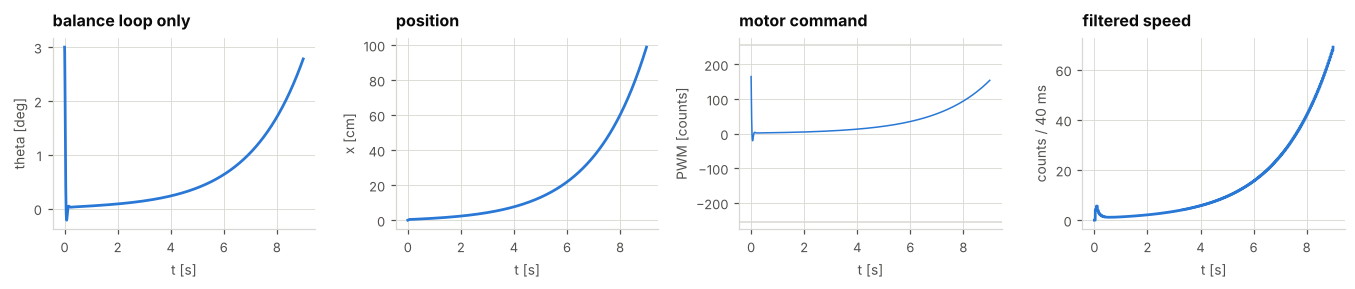

after 9 s: tilt +2.78 deg, speed 0.49 m/s, travelled 99 cm


In [4]:
ideal = tb.SensorModel(ideal=True)
bal_only = tb.simulate(p, speed_enabled=False, theta0_deg=3, t_end=9, sensors=ideal)
axs = tb.plot_run(bal_only, "balance loop only")
plt.show()
print(f"after 9 s: tilt {bal_only.theta_deg[-1]:+.2f} deg, speed {bal_only.v[-1]:.2f} m/s, "
      f"travelled {bal_only.x[-1]*100:.0f} cm")

## 2.3 · The speed loop — why the feedback is *positive*

The firmware adds a second term proportional to the wheel speed, and the sign is
surprising. In `BalanceCar.h`:

```cpp
speed_control_output = -kp_speed * speed_filter - ki_speed * car_speed_integeral;
pwm = balance_control_output - speed_control_output;     // = balance + kp_speed*speed + ...
```

Rolling forward **adds** forward PWM. That looks like it should run away even
faster. It does not, because of how a balancing robot brakes:

1. To slow down, the robot needs a backward force on the body — it must **lean back**.
2. The only way to lean back is to move the wheels **further forward**, out from
   under the body.
3. So the first response to "too fast forward" has to be "wheels even faster
   forward". Then the balance loop, seeing a backward lean, drives backward and the
   robot decelerates.

A system that must first go the wrong way is called *non-minimum-phase*. The
speed loop does not fight the balance loop — it **feeds it a tilt error on
purpose**: effectively the speed term shifts the angle the balance loop is
aiming for. That is why this structure is called a *cascade*.

Proof by simulation — stock sign against the "intuitive" negative sign:

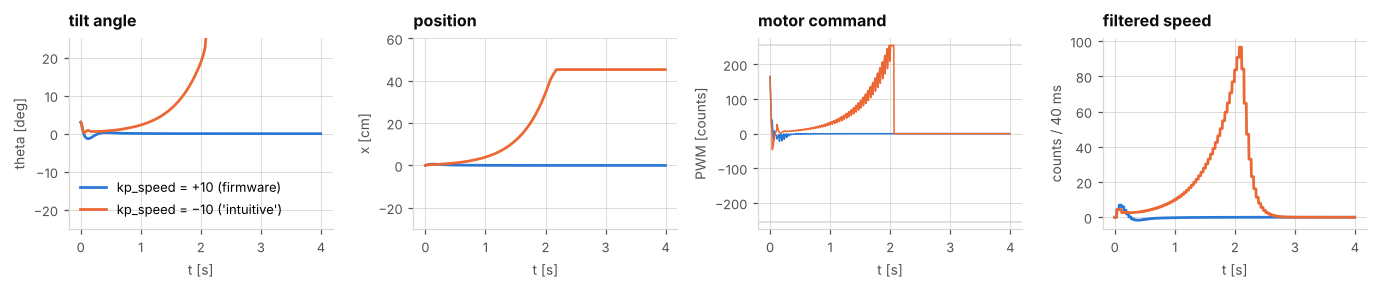

firmware sign : <Result 4.0 s  fell=False  max|theta|=3.0 deg  x_end=-0.0 cm>
flipped sign  : <Result 4.0 s  fell=True  max|theta|=75.8 deg  x_end=45.3 cm>


In [5]:
pos = tb.simulate(p, g.with_(ki_speed=0), theta0_deg=3, t_end=4, sensors=ideal)
neg = tb.simulate(p, g.with_(kp_speed=-g.kp_speed, ki_speed=0), theta0_deg=3, t_end=4, sensors=ideal)
axs = tb.plot_run(pos, "tilt angle", label="kp_speed = +10 (firmware)")
tb.plot_run(neg, axs=axs, label="kp_speed = −10 ('intuitive')")
axs[0].set_ylim(-25, 25); axs[1].set_ylim(-30, 60); axs[0].legend()
plt.show()
print("firmware sign :", pos)
print("flipped sign  :", neg)

With the firmware's sign the robot comes to rest after rolling a short distance.
With the flipped sign it tips over within a second or two.

## 2.4 · The integral term: stand *here*, and forgive a wrong zero

The P-only speed loop brings the speed to zero only if upright really is
$\theta = 0$ for the sensor. On a real robot it never is: the IMU is mounted a
little crooked, the battery sits off-centre. Then "angle = 0" means "leaning
slightly", the robot must roll steadily to hold that lean, and it creeps away.

The integral of speed is distance. Feeding it back makes the robot return to
where it started — and, as a side effect, lets it find the true balance angle by
itself. Simulated with a 1.5° sensor mounting offset:

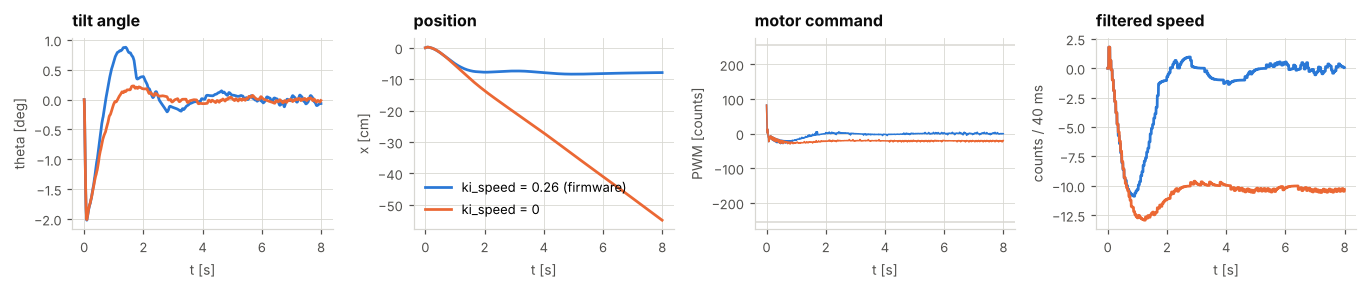

with integral   : final speed +0.0 cm/s, parked at x = -7.9 cm
without integral: final speed -7.1 cm/s and still going


In [6]:
off = tb.SensorModel(mount_offset_deg=1.5)
with_i = tb.simulate(p, g, theta0_deg=0, t_end=8, sensors=off)
no_i = tb.simulate(p, g.with_(ki_speed=0), theta0_deg=0, t_end=8, sensors=off)
axs = tb.plot_run(with_i, "tilt angle", label="ki_speed = 0.26 (firmware)")
tb.plot_run(no_i, axs=axs, label="ki_speed = 0")
axs[1].legend()
plt.show()
print(f"with integral   : final speed {with_i.v[-1]*100:+.1f} cm/s, parked at x = {with_i.x[-1]*100:+.1f} cm")
print(f"without integral: final speed {no_i.v[-1]*100:+.1f} cm/s and still going")

The firmware also uses the integral to **drive**: the commanded speed is simply
subtracted inside the integral (`car_speed_integeral += -setting_car_speed`), so
the robot moves until measured and commanded speed cancel.

## 2.5 · Two loops, two speeds — and why the filter matters

Collect what the firmware computes:

$$u = \underbrace{k_{p,b}\,\theta + k_{d,b}\,\dot\theta}_{\text{balance: every 5 ms}}
  \;+\; \underbrace{k_{p,s}\,\bar v + k_{i,s}\textstyle\sum \bar v}_{\text{speed: every 40 ms, low-pass filtered}}$$

All four states ($x$ via the sum, $\dot x$, $\theta$, $\dot\theta$) are fed back.
It is tempting to read this as plain full-state feedback $u = K s$.
`tb.firmware_to_state_feedback` does that conversion — and the result is a warning:

In [7]:
K_fw = tb.firmware_to_state_feedback(p, g)
print("firmware gains as state feedback  K = [x, v, theta, omega]:")
print("  ", K_fw)
ev = np.linalg.eigvals(A + B @ K_fw[None, :])
print("\nclosed-loop poles if the speed terms acted instantly:")
for e in sorted(ev, key=lambda z: z.real):
    print(f"  {e.real:8.2f} {e.imag:+8.2f}j")

firmware gains as state feedback  K = [x, v, theta, omega]:
   [ 963.4813 1482.2789 3118.9913   -6.6845]

closed-loop poles if the speed terms acted instantly:
     -0.98    +0.78j
     -0.98    -0.78j
     31.91   +37.66j
     31.91   -37.66j


Unstable! If the speed feedback acted *instantly*, the stock gains would not
work: the positive speed feedback is so strong that it would overpower the
balance loop at high frequency.

What saves it is in three unremarkable lines of firmware: the speed loop runs only
every 8th tick, and the speed is low-pass filtered
(`speed_filter = 0.7*old + 0.3*new`, a time constant of roughly 0.1 s). The speed
loop is made **deliberately slow**, so that at the frequencies where the balance
loop works, the speed term is almost constant. This *time-scale separation* is
the key design rule of every cascade:

> the inner loop (balance) must be several times faster than the outer loop (speed).

`tb.lifted_closed_loop` models the real thing exactly — 5 ms ticks, 40 ms speed
update, filter — as one matrix $\Phi$ per 40 ms frame. Stable means all
eigenvalues inside the unit circle. Each $z$ converts to an equivalent
continuous pole $s = \ln(z)/T$:

with the firmware's filter (0.7):  max |z| = 0.947
     |z| = 0.947   ->  s =  -1.36  +0.78j 1/s   (time constant   736 ms)
     |z| = 0.654   ->  s = -10.61  +9.37j 1/s   (time constant    94 ms)
without the filter       (0.0):  max |z| = 1.135
     |z| = 1.135   ->  s =   3.17 +21.91j 1/s   UNSTABLE
     |z| = 0.959   ->  s =  -1.06  +0.77j 1/s   (time constant   946 ms)
     |z| = 0.379   ->  s = -24.22 +78.54j 1/s   (time constant    41 ms)


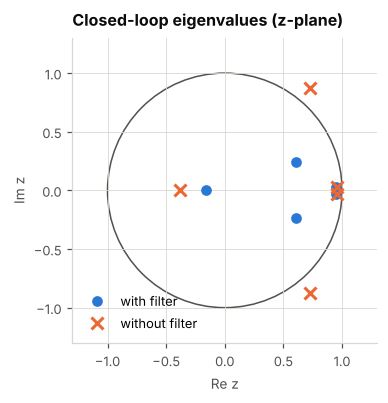

In [8]:
def show_modes(filt, label):
    ev = np.linalg.eigvals(tb.lifted_closed_loop(p, g, speed_filter=filt))
    ev = np.delete(ev, np.argmin(np.abs(ev - 1)))           # drop the trivial x-shift mode
    print(f"{label}:  max |z| = {np.max(np.abs(ev)):.3f}")
    for z in sorted(ev, key=lambda z: -abs(z)):
        if z.imag < -1e-9 or abs(z) < 0.3:                   # skip conjugates and very fast modes
            continue
        s = np.log(complex(z)) / 0.040
        print(f"     |z| = {abs(z):.3f}   ->  s = {s.real:6.2f} {s.imag:+6.2f}j 1/s   "
              f"(time constant {-1/s.real*1e3:5.0f} ms)" if s.real < 0 else
              f"     |z| = {abs(z):.3f}   ->  s = {s.real:6.2f} {s.imag:+6.2f}j 1/s   UNSTABLE")
    return ev

ev_f = show_modes(0.7, "with the firmware's filter (0.7)")
ev_n = show_modes(0.0, "without the filter       (0.0)")

fig, ax = plt.subplots(figsize=(3.6, 3.6))
ax.add_patch(plt.Circle((0, 0), 1, fill=False, color=INK2, lw=1))
ax.plot(ev_f.real, ev_f.imag, "o", label="with filter")
ax.plot(ev_n.real, ev_n.imag, "x", ms=8, mew=2, label="without filter")
ax.set_aspect("equal"); ax.set_xlim(-1.3, 1.3); ax.set_ylim(-1.3, 1.3); ax.legend(loc="lower left")
tidy(ax, "Closed-loop eigenvalues (z-plane)", "Re z", "Im z")
plt.show()

With the filter there are two clearly separated motions: a **fast balance mode**
(time constant around 0.1 s) and a **slow position mode** (around 0.7 s) — the
robot catches its tilt quickly and then drifts back to its spot at leisure.
Remove the filter and a pair of eigenvalues leaves the unit circle.

## 2.6 · Discrete time: how fast must the loop be?

The controller measures, computes and then *holds* its output for one period.
Holding is a delay of half a period on average, and delay eats stability. The
faster the plant (stiffer $k_p$), the less delay it tolerates. Same gains,
different loop periods (the speed loop is kept at 40 ms):

In [9]:
kps = [55, 100, 150, 200, 300]
print("largest |z| (below 1 = stable)\n")
print("loop period    kp_balance = " + "".join(f"{k:>9}" for k in kps))
for dt, div in [(0.005, 8), (0.010, 4), (0.020, 2), (0.040, 1)]:
    q = p.with_(dt=dt, speed_div=div)
    row = [tb.stability_margin(q, g.with_(kp_balance=k)) for k in kps]
    cells = "".join(f"{m:8.2f}" + ("*" if m >= 1 else " ") for m in row)
    print(f"   {dt*1e3:4.0f} ms                  {cells}")
print("\n* = unstable")

largest |z| (below 1 = stable)

loop period    kp_balance =        55      100      150      200      300
      5 ms                      0.95     0.98     0.99     0.99     0.99 
     10 ms                      0.95     0.98     0.99     0.99     1.07*
     20 ms                      0.95     0.98     1.05*    1.23*    1.91*
     40 ms                      0.95     0.99     1.58*    3.29*    6.08*

* = unstable


At 5 ms the loop tolerates a balance gain more than five times the stock value.
At 20 ms the ceiling has come down to somewhere between two and three times
stock, and the slower the loop, the more violent the instability beyond it. This is why `balanceCar()` runs in a timer interrupt (`MsTimer2`,
5 ms) and not in `loop()`: the period must be short **and constant**. The same
table also explains a classic hardware bug — `Serial.print` or `delay` inside the
control path makes the robot wobble.

## 2.7 · Measuring the tilt: accelerometer + gyro

The controller needs $\theta$ and $\dot\theta$. The MPU-6050 offers two imperfect sources:

| sensor | gives | good | bad |
|---|---|---|---|
| accelerometer | direction of gravity → `atan2(ay, az)` | no drift, correct on average | noisy; fooled by every acceleration of the robot itself |
| gyroscope | angular rate → integrate to get angle | smooth, fast, immune to linear acceleration | integration drifts with any bias |

They fail in opposite frequency ranges, so combine them: trust the gyro for fast
changes and the accelerometer for the long-term average. The one-line version is
the **complementary filter** (it is in `KalmanFilter.cpp` as `Yiorderfilter`,
though the firmware does not use its result):

$$\hat\theta_k = (1-K)\,(\hat\theta_{k-1} + \omega_{gyro}\,\Delta t) + K\,\theta_{acc}$$

The firmware uses a small **Kalman filter** with two states — the angle and the
gyro bias. It has the same structure (predict with gyro, correct with
accelerometer) but computes the blending gain from assumed noise levels
(`Q_angle`, `Q_gyro`, `R_angle`) and, as a bonus, estimates the gyro bias.
`tb.KalmanAngle` is a line-by-line port. A push test with realistic sensor noise
and a 2 °/s gyro bias:

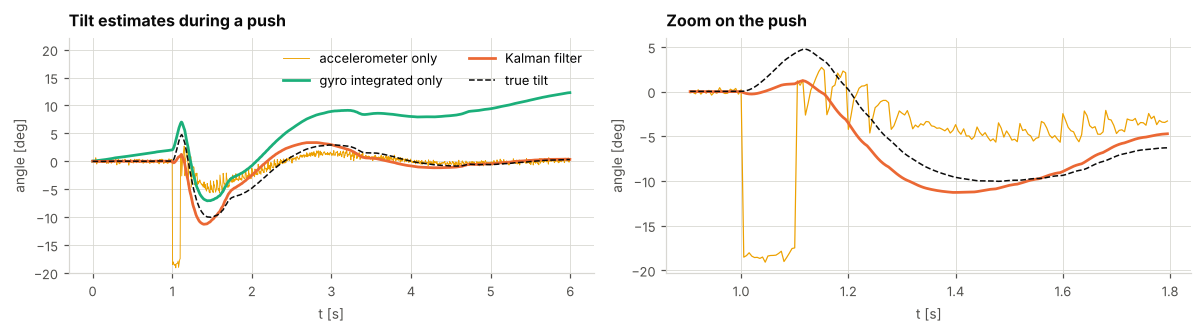

steady-state Kalman gain K0 = 0.0089 per tick
-> behaves like a complementary filter with time constant dt/K0 = 0.56 s
largest estimation error during the push: 3.9 deg


In [10]:
noisy = tb.SensorModel(gyro_bias_dps=2.0)
run = tb.simulate(p, g, theta0_deg=0, t_end=6, push=(1.0, 0.1, 3.0), sensors=noisy)
gyro_only = np.cumsum(run.omega * 180 / np.pi + noisy.gyro_bias_dps) * p.dt

fig, axs = plt.subplots(1, 2, figsize=(11, 3.1))
axs[0].plot(run.t, run.angle_acc, lw=0.6, color=SERIES[3], label="accelerometer only")
axs[0].plot(run.t, gyro_only, color=SERIES[2], label="gyro integrated only")
axs[0].plot(run.t, run.angle_est, color=SERIES[1], label="Kalman filter")
axs[0].plot(run.t, run.theta_deg, color=INK, lw=1, ls="--", label="true tilt")
axs[0].set_ylim(-20, 22); axs[0].legend(ncol=2, loc="upper right")
tidy(axs[0], "Tilt estimates during a push", "t [s]", "angle [deg]")
m = (run.t > 0.9) & (run.t < 1.8)
axs[1].plot(run.t[m], run.angle_acc[m], lw=0.8, color=SERIES[3])
axs[1].plot(run.t[m], run.angle_est[m], color=SERIES[1])
axs[1].plot(run.t[m], run.theta_deg[m], color=INK, lw=1, ls="--")
tidy(axs[1], "Zoom on the push", "t [s]", "angle [deg]")
plt.tight_layout(); plt.show()

kf = tb.KalmanAngle()
for _ in range(4000):
    kf.update(0.0, 0.0, p.dt)
print(f"steady-state Kalman gain K0 = {kf.K0:.4f} per tick")
print(f"-> behaves like a complementary filter with time constant dt/K0 = {p.dt/kf.K0:.2f} s")
err = run.angle_est - run.theta_deg
print(f"largest estimation error during the push: {np.max(np.abs(err)):.1f} deg")

- The accelerometer angle is wildly wrong exactly when it matters — during the
  push, when the robot accelerates. A horizontal acceleration of 0.3 g reads as
  a tilt of 17°.
- The integrated gyro has the right shape but walks away at 2 °/s.
- The Kalman estimate has no drift and is far better than either source — but
  it is not perfect. During the push it is dragged several degrees towards the
  wrong accelerometer reading, and the controller acts on that wrong angle.

With the firmware's noise settings the filter settles to a blending gain that
corresponds to a time constant of about half a second: for anything faster the
angle is essentially gyro, for anything slower it is accelerometer. Half a
second is fairly short, which is why a sharp push leaks through. `R_angle` is the
knob: larger means "trust the accelerometer less" (exercise 4).

One detail to remember for the hardware: the D-term does **not** use a filtered
rate. It takes the raw gyro reading minus a fixed offset
(`Gyro_x = (gx - 128.1) / 131`). Gyro noise goes straight into the PWM,
multiplied by `kd_balance`.

## 2.8 · The textbook alternative: full-state feedback and LQR

If all four states were measured cleanly at 5 ms, the classic design would be
$u = K s$ with $K$ from a linear-quadratic regulator: choose how much you dislike
position error, tilt, and control effort ($Q$, $R$), and LQR returns the optimal
gain vector. It is a useful reference for "how good could it be":

LQR gain  K = [x, v, theta, omega] = [547.7226 782.2691 736.7292  75.8682]
closed-loop poles: [-25.79+0.j  -7.83+0.j  -5.72+0.j  -1.87+0.j]


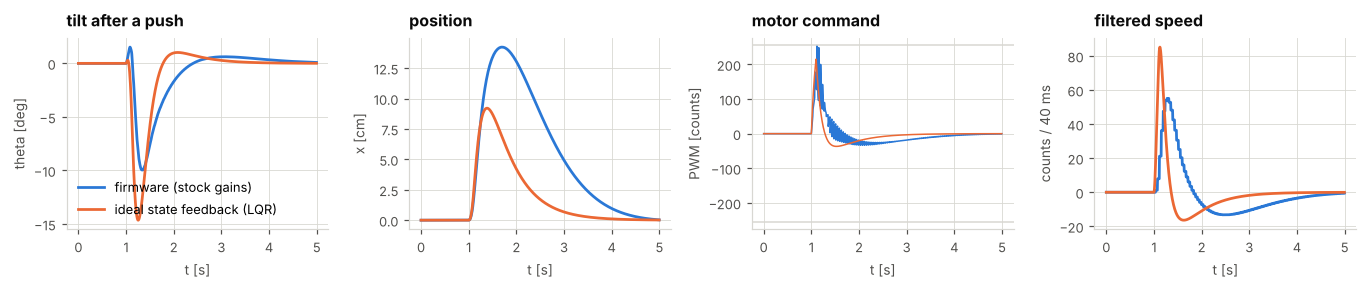


LQR gains translated into firmware units:
   kp_balance 13.2   kd_balance 1.78   kp_speed 5.3   ki_speed 0.148
largest |z| of those gains in the real firmware structure: 1.019   (stock gains: 0.947)


In [11]:
K_lqr = tb.lqr(p, Q=np.diag([3e5, 1.0, 2000.0, 1.0]), R=1.0)
print("LQR gain  K = [x, v, theta, omega] =", K_lqr)
print("closed-loop poles:", np.round(np.linalg.eigvals(A + B @ K_lqr[None, :]), 2))

push = (1.0, 0.1, 3.0)
fw = tb.simulate(p, g, theta0_deg=0, t_end=5, push=push, sensors=ideal)
sf = tb.simulate(p, controller="state", K=K_lqr, theta0_deg=0, t_end=5, push=push, sensors=ideal)
axs = tb.plot_run(fw, "tilt after a push", label="firmware (stock gains)")
tb.plot_run(sf, axs=axs, label="ideal state feedback (LQR)")
axs[0].legend()
plt.show()

g_lqr = tb.state_feedback_to_firmware(p, K_lqr)
print("\nLQR gains translated into firmware units:")
print(f"   kp_balance {g_lqr.kp_balance:.1f}   kd_balance {g_lqr.kd_balance:.2f}   "
      f"kp_speed {g_lqr.kp_speed:.1f}   ki_speed {g_lqr.ki_speed:.3f}")
print(f"largest |z| of those gains in the real firmware structure: "
      f"{tb.stability_margin(p, g_lqr):.3f}   (stock gains: {tb.stability_margin(p, g):.3f})")

Two honest observations:

1. The LQR also uses **positive** feedback on speed and position (look at the
   signs of the first two entries). The odd sign of 2.3 is not an Elegoo quirk —
   it is what the physics demands.
2. Typing the LQR numbers into the firmware does **not** reproduce the LQR. The
   firmware's speed path is slow and filtered; gains designed for an instant
   speed measurement end up outside the unit circle there. And an instant speed measurement
   is not available: at walking pace the encoder delivers only a handful of
   counts per 5 ms tick. That coarse, noisy speed signal is the practical reason
   the firmware uses the slow cascade instead.

So the cascade is not the poor man's LQR; it is a structure that fits the sensors.

## 2.9 · Take-aways

- **Balance loop (PD on tilt):** P is a spring that must beat gravity, D is a damper.
  Fast: around 0.1 s.
- **Speed loop (PI on wheel speed):** positive feedback, because the robot must
  first move the wheels the "wrong" way to lean against its motion. Slow by
  design: around 0.7 s.
- **Integral:** returns the robot to its spot and absorbs a wrong zero angle.
- **Time-scale separation** between the loops is what makes the stock gains work;
  the 0.7/0.3 speed filter is part of the controller, not decoration.
- **Loop period** limits how stiff the balance loop can be; 5 ms leaves room.
- **Tilt estimate** = gyro for fast, accelerometer for slow.

## Exercises

1. In 2.1, what $k_d$ would give $\zeta = 0.7$ in the toy model? Put it into
   `tb.stability_margin(p, g.with_(kd_balance=...))`. Does the full model care? Why (think back-EMF)?
2. Repeat the sign experiment of 2.3 with `ki_speed` also flipped. Faster or slower to fall?
3. Use `tb.lifted_closed_loop(p, g, speed_filter=a)` for `a` from 0 to 0.9. At
   which filter coefficient does the loop become stable? Where is it best?
4. Compute the equivalent time constant for `tb.KalmanAngle(R_angle=0.05)` and
   for `R_angle=5`. Which one would be dragged less by a push? What would you pay for it?
5. Play with the LQR weights: make position 10× more important. What happens to
   the gains and to the slow pole?